# Speech emotion recognition on simulated messy audio

**Question.** Does training a small GRU or CRNN on extra *degraded copies* of CREMA-D train speech make it more robust than training on clean speech only?


## 0. Setup

Imports, random seed, relative paths, and the five emotion names. Run this first.


In [1]:
from __future__ import annotations

import hashlib
import os
import random
import subprocess
from pathlib import Path

import imageio_ffmpeg
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
import tensorflow as tf
from scipy.signal import butter, sosfilt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from tqdm import tqdm

SEED = 8
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


def find_repo_root() -> Path:
    # Prefer the folder that contains this notebook (Cursor / VS Code).
    nb = globals().get("__vsc_ipynb_file__")
    if isinstance(nb, str) and Path(nb).exists():
        return Path(nb).resolve().parent
    cwd = Path.cwd().resolve()
    if cwd.name == "Affective-Comp-SER":
        return cwd
    nested = cwd / "Affective-Comp-SER"
    if nested.is_dir():
        return nested
    return cwd


def find_data_root(repo: Path) -> Path:
    cwd = Path.cwd().resolve()
    for p in (cwd, repo, repo.parent, cwd.parent):
        if (p / "datasets" / "AudioWAV").is_dir():
            return p
    return repo


def relpath(p) -> str:
    p = Path(p).resolve()
    for root in (REPO_ROOT, DATA_ROOT):
        try:
            return p.relative_to(root.resolve()).as_posix()
        except ValueError:
            continue
    return p.name


def audio_path(p) -> Path:
    q = Path(p)
    return q if q.is_absolute() else DATA_ROOT / q


REPO_ROOT = find_repo_root()
DATA_ROOT = find_data_root(REPO_ROOT)
AUDIO_DIR = DATA_ROOT / "datasets" / "AudioWAV"
CACHE_DIR = DATA_ROOT / "cache"
MODEL_DIR = DATA_ROOT / "models"
OUT_DIR = REPO_ROOT / "outputs"
for d in (CACHE_DIR, MODEL_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

VIDEO_PATH = DATA_ROOT / "test_video" / (
    "Yes_We_Can-_People_Share_Their_Most_Memorable_Moments_from_the_Obama_Presidency.webm"
)

EMOTIONS = ["angry", "disgust", "happy", "neutral", "sad"]
EMO_FROM_CODE = {"ANG": "angry", "DIS": "disgust", "HAP": "happy", "NEU": "neutral", "SAD": "sad"}

SR = 16000
MAX_DUR = 3.0
N_MFCC = 13
BATCH_SIZE = 32
EPOCHS = 50
LR = 1e-3
PATIENCE = 5

# Filled in later if a model is actually trained this session (not loaded).
hist_gru = hist_crnn = hist_gru_m = hist_crnn_m = None

print("TensorFlow", tf.__version__)
print("Repo root:", relpath(REPO_ROOT) if REPO_ROOT != Path.cwd().resolve() else ".")
print("Audio dir:", relpath(AUDIO_DIR), "OK" if AUDIO_DIR.is_dir() else "MISSING")
print("Demo video:", relpath(VIDEO_PATH), "OK" if VIDEO_PATH.is_file() else "MISSING")


TensorFlow 2.21.0
Repo root: .
Audio dir: datasets/AudioWAV OK
Demo video: test_video/Yes_We_Can-_People_Share_Their_Most_Memorable_Moments_from_the_Obama_Presidency.webm OK


## 1. Read CREMA-D filenames

Each file looks like `1001_DFA_ANG_XX.wav`: speaker, sentence, emotion, intensity. We keep the five emotions that overlap with typical “in the wild” sets and drop fear.


In [2]:
rows = []
wavs = sorted(AUDIO_DIR.glob("*.wav"))
if not wavs:
    raise FileNotFoundError("No wav files in datasets/AudioWAV")

for path in wavs:
    parts = path.stem.split("_")
    if len(parts) < 3:
        continue
    speaker, sentence, emo_code = parts[0], parts[1], parts[2]
    if emo_code not in EMO_FROM_CODE:
        continue
    rows.append({
        "path": path.resolve().relative_to(DATA_ROOT).as_posix(),
        "speaker": speaker,
        "sentence": sentence,
        "emotion": EMO_FROM_CODE[emo_code],
        "intensity": parts[3] if len(parts) > 3 else "",
    })

meta = pd.DataFrame(rows)
print(f"{len(wavs)} wavs on disk, {len(meta)} kept, {meta['speaker'].nunique()} speakers")
print(meta["emotion"].value_counts().reindex(EMOTIONS))


7442 wavs on disk, 6171 kept, 91 speakers
emotion
angry      1271
disgust    1271
happy      1271
neutral    1087
sad        1271
Name: count, dtype: int64


## 2. Split by speaker

Shuffle the 91 speaker IDs and assign about 80% / 10% / 10% of *speakers*, not clips. Every clip from a speaker stays in that split, so the test set is people the model has never heard.


In [3]:
rng = np.random.default_rng(SEED)
speakers = np.array(sorted(meta["speaker"].unique()))
rng.shuffle(speakers)

n = len(speakers)
n_test = max(1, round(n * 0.10))
n_val = max(1, round(n * 0.10))
test_spk = set(speakers[:n_test])
val_spk = set(speakers[n_test:n_test + n_val])
train_spk = set(speakers[n_test + n_val:])

# Fail loudly if a speaker leaked across splits.
assert train_spk.isdisjoint(val_spk) and train_spk.isdisjoint(test_spk) and val_spk.isdisjoint(test_spk)

def assign_split(spk):
    if spk in train_spk:
        return "train"
    if spk in val_spk:
        return "val"
    return "test"

meta["split"] = meta["speaker"].map(assign_split)
print("Speakers train/val/test:", len(train_spk), len(val_spk), len(test_spk))
print(meta["split"].value_counts().reindex(["train", "val", "test"]))
print(pd.crosstab(meta["split"], meta["emotion"]).reindex(["train", "val", "test"])[EMOTIONS])

meta.sort_values(["split", "speaker", "path"]).to_csv(OUT_DIR / "speaker_split.csv", index=False)


Speakers train/val/test: 73 9 9
split
train    4948
val       611
test      612
Name: count, dtype: int64
emotion  angry  disgust  happy  neutral   sad
split                                        
train     1019     1019   1019      872  1019
val        126      126    126      107   126
test       126      126    126      108   126


## 3. Picture of the split

A quick bar chart for the report: how many clips landed in each split, and whether the five emotions stayed roughly balanced.


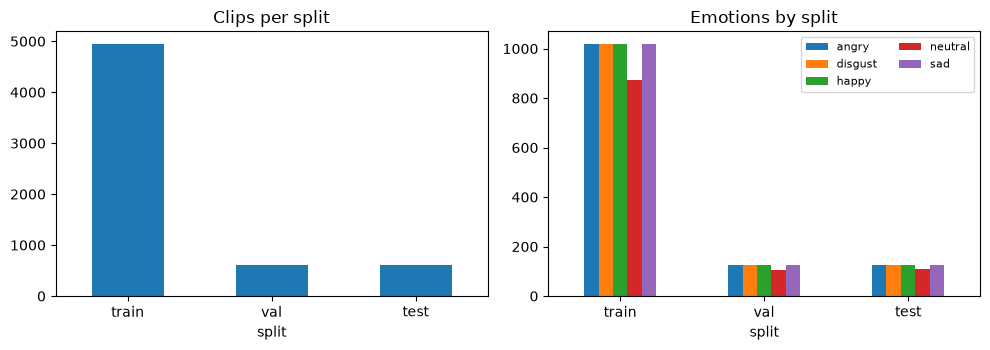

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
meta["split"].value_counts().reindex(["train", "val", "test"]).plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Clips per split")
pd.crosstab(meta["split"], meta["emotion"]).reindex(["train", "val", "test"])[EMOTIONS].plot(
    kind="bar", ax=axes[1], rot=0
)
axes[1].set_title("Emotions by split")
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_split_counts.png", dpi=150)
plt.show()
plt.close()


## 4. MFCC features

16 kHz, pad/trim to 3 seconds, 13 MFCCs → shape about `(94, 13)`. Helpers below are reused for clean audio, messy copies, and the demo.


In [5]:
le = LabelEncoder()
le.fit(EMOTIONS)  # fixed order: angry, disgust, happy, neutral, sad


def load_wav(path: str) -> np.ndarray:
    y, sr = sf.read(str(audio_path(path)), dtype="float32", always_2d=False)
    if y.ndim > 1:
        y = y.mean(axis=1)
    if sr != SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR)
    return y.astype(np.float32)


def mfcc_from_wav(y: np.ndarray) -> np.ndarray:
    max_len = int(SR * MAX_DUR)
    if len(y) > max_len:
        y = y[:max_len]
    else:
        y = np.pad(y, (0, max_len - len(y)))
    return librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC).T.astype(np.float32)


def extract_mfcc(path: str) -> np.ndarray:
    return mfcc_from_wav(load_wav(path))


Build (or load) the **clean** train/val/test arrays. First run caches them under `cache/mfcc_clean.npz` 


In [6]:
CACHE_PATH = CACHE_DIR / "mfcc_clean.npz"


def features_for(split: str):
    sub = meta[meta["split"] == split].reset_index(drop=True)
    X = np.stack([extract_mfcc(p) for p in tqdm(sub["path"], desc=f"MFCC {split}")])
    y = le.transform(sub["emotion"].to_numpy())
    return X, y


if CACHE_PATH.exists():
    data = np.load(CACHE_PATH)
    X_tr, y_tr = data["X_tr"], data["y_tr"]
    X_val, y_val = data["X_val"], data["y_val"]
    X_te, y_te = data["X_te"], data["y_te"]
    print("Loaded", relpath(CACHE_PATH))
else:
    X_tr, y_tr = features_for("train")
    X_val, y_val = features_for("val")
    X_te, y_te = features_for("test")
    np.savez_compressed(CACHE_PATH, X_tr=X_tr, y_tr=y_tr, X_val=X_val, y_val=y_val, X_te=X_te, y_te=y_te)
    print("Wrote", relpath(CACHE_PATH))

# CRNN wants a channel dim: (time, mfcc, 1)
X_tr_c, X_val_c, X_te_c = X_tr[..., np.newaxis], X_val[..., np.newaxis], X_te[..., np.newaxis]
print("Train", X_tr.shape, "Val", X_val.shape, "Test", X_te.shape)


MFCC train:   0%|          | 0/4948 [00:00<?, ?it/s]/Users/nvo/stuff/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
MFCC test: 100%|██████████| 612/612 [00:01<00:00, 599.32it/s]


Wrote cache/mfcc_clean.npz
Train (4948, 94, 13) Val (611, 94, 13) Test (612, 94, 13)


## 5. Models and training helpers

Two small networks from the original prototype: a stacked GRU, and a tiny CRNN (conv frontend + bidirectional LSTM). Same sizes, Adam, early stopping on val loss.

Training logs **one line every 5 epochs** (plus the first and last), not every batch.



In [7]:
def build_gru(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Masking(mask_value=0.0),
        layers.GRU(128, return_sequences=True),
        layers.Dropout(0.3),
        layers.GRU(64),
        layers.Dropout(0.3),
        layers.Dense(len(EMOTIONS), activation="softmax"),
    ])
    model.compile(loss="sparse_categorical_crossentropy", optimizer=Adam(LR), metrics=["accuracy"])
    return model


def build_crnn(input_shape_hwc):
    model = models.Sequential([
        layers.Input(shape=input_shape_hwc),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPool2D((2, 2)),
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPool2D((2, 2)),
        layers.Permute((1, 3, 2)),
        layers.TimeDistributed(layers.Flatten()),
        layers.Bidirectional(layers.LSTM(128, return_sequences=False)),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(len(EMOTIONS), activation="softmax"),
    ])
    model.compile(loss="sparse_categorical_crossentropy", optimizer=Adam(LR), metrics=["accuracy"])
    return model


In [8]:
class SparseEpochLog(tf.keras.callbacks.Callback):
    # One line every `every` epochs, not Keras's per-batch bar.

    def __init__(self, every=5):
        super().__init__()
        self.every = every

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        n = epoch + 1
        if n == 1 or n % self.every == 0:
            print(
                f"epoch {n}  loss={logs.get('loss'):.4f}  acc={logs.get('accuracy'):.3f}  "
                f"val_loss={logs.get('val_loss'):.4f}  val_acc={logs.get('val_accuracy'):.3f}"
            )

    def on_train_end(self, logs=None):
        logs = logs or {}
        # Always print the last epoch (early stopping may not land on a multiple of 5).
        if logs:
            print(
                f"last  loss={logs.get('loss'):.4f}  acc={logs.get('accuracy'):.3f}  "
                f"val_loss={logs.get('val_loss'):.4f}  val_acc={logs.get('val_accuracy'):.3f}"
            )


def train_model(model, X_train, y_train, X_v, y_v, ckpt_path):
    history = model.fit(
        X_train, y_train,
        validation_data=(X_v, y_v),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0,  # no per-batch bar
        callbacks=[
            EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
            ModelCheckpoint(ckpt_path, save_best_only=True, monitor="val_loss", verbose=0),
            SparseEpochLog(every=5),
        ],
    )
    model.save(ckpt_path)
    print(f"stopped after {len(history.history['loss'])} epochs → {relpath(ckpt_path)}")
    return history


def plot_cm(y_true, y_pred, title, out_path):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(EMOTIONS)))
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=EMOTIONS, yticklabels=EMOTIONS)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(out_path, dpi=150)
    plt.show()
    plt.close()
    return cm


def evaluate(model, X, y, title, cm_path):
    y_pred = np.argmax(model.predict(X, verbose=0), axis=1)
    acc = accuracy_score(y, y_pred)
    macro_f1 = f1_score(y, y_pred, average="macro", zero_division=0)
    per = f1_score(y, y_pred, average=None, labels=np.arange(len(EMOTIONS)), zero_division=0)
    print(title)
    print(classification_report(y, y_pred, target_names=EMOTIONS, digits=3, zero_division=0))
    plot_cm(y, y_pred, title, cm_path)
    return {"accuracy": acc, "macro_f1": macro_f1, "per_class_f1": per}


def load_or_train(ckpt, build_fn, X_train, y_train, X_v, y_v):
    # Reuse a saved checkpoint so a second run does not retrain.
    ckpt = str(ckpt)
    if Path(ckpt).exists():
        print("Loaded", relpath(ckpt))
        return tf.keras.models.load_model(ckpt), None
    model = build_fn()
    hist = train_model(model, X_train, y_train, X_v, y_v, ckpt)
    return model, hist


## 6. Clean GRU baseline

Train (or load) the GRU on **clean** train clips only. Then score it on clean held-out speakers. This is the “before” number.


In [9]:
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)
gru, hist_gru = load_or_train(
    MODEL_DIR / "gru_clean.keras",
    lambda: build_gru(X_tr.shape[1:]),
    X_tr, y_tr, X_val, y_val,
)


epoch 1  loss=1.3070  acc=0.434  val_loss=1.1753  val_acc=0.543
epoch 5  loss=1.0410  acc=0.573  val_loss=1.1508  val_acc=0.543
epoch 10  loss=0.8892  acc=0.652  val_loss=1.1622  val_acc=0.556
last  loss=0.8664  acc=0.662  val_loss=1.2050  val_acc=0.552
stopped after 11 epochs → models/gru_clean.keras


GRU clean → CREMA-D clean test
              precision    recall  f1-score   support

       angry      0.827     0.643     0.723       126
     disgust      0.526     0.556     0.541       126
       happy      0.625     0.595     0.610       126
     neutral      0.464     0.602     0.524       108
         sad      0.686     0.659     0.672       126

    accuracy                          0.611       612
   macro avg      0.626     0.611     0.614       612
weighted avg      0.630     0.611     0.617       612



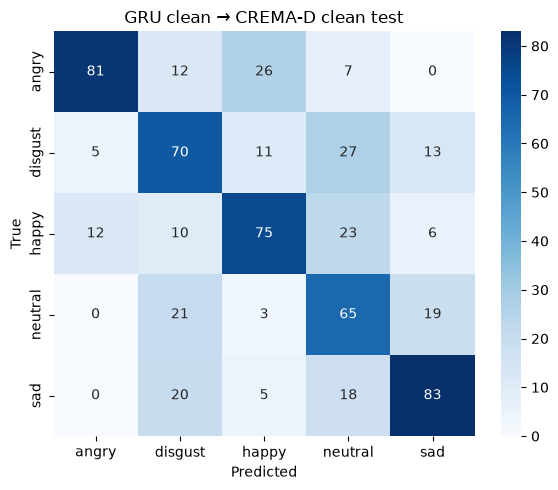

{'accuracy': 0.6111111111111112, 'macro_f1': 0.6139538499061669, 'per_class_f1': array([0.72321429, 0.54054054, 0.6097561 , 0.52419355, 0.67206478])}


In [10]:
gru_clean_metrics = evaluate(
    gru, X_te, y_te,
    "GRU clean → CREMA-D clean test",
    OUT_DIR / "cm_gru_clean_cremad.png",
)
print(gru_clean_metrics)


## 7. Clean CRNN baseline

Same split and labels as the GRU, extra channel dimension for the conv layers.


In [11]:
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)
crnn, hist_crnn = load_or_train(
    MODEL_DIR / "crnn_clean.keras",
    lambda: build_crnn(X_tr_c.shape[1:]),
    X_tr_c, y_tr, X_val_c, y_val,
)


epoch 1  loss=1.3623  acc=0.408  val_loss=1.2232  val_acc=0.488
epoch 5  loss=1.0889  acc=0.561  val_loss=1.1083  val_acc=0.570
epoch 10  loss=0.9141  acc=0.649  val_loss=1.1195  val_acc=0.599
last  loss=0.8750  acc=0.663  val_loss=1.1262  val_acc=0.574
stopped after 11 epochs → models/crnn_clean.keras


CRNN clean → CREMA-D clean test
              precision    recall  f1-score   support

       angry      0.910     0.643     0.753       126
     disgust      0.436     0.540     0.482       126
       happy      0.586     0.516     0.549       126
     neutral      0.607     0.500     0.548       108
         sad      0.587     0.778     0.669       126

    accuracy                          0.598       612
   macro avg      0.625     0.595     0.600       612
weighted avg      0.626     0.598     0.602       612



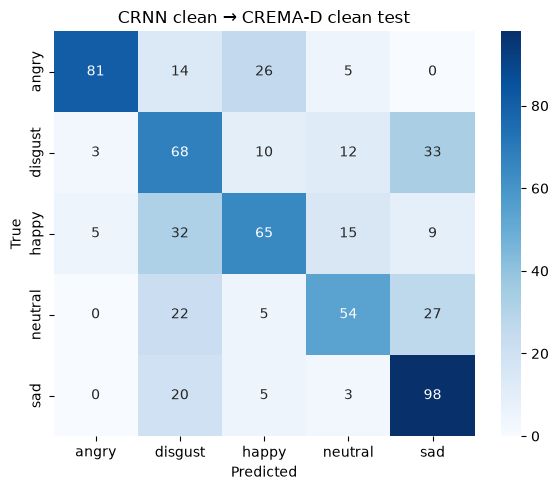

{'accuracy': 0.5980392156862745, 'macro_f1': 0.6002892824332337, 'per_class_f1': array([0.75348837, 0.4822695 , 0.54852321, 0.54822335, 0.66894198])}


In [12]:
crnn_clean_metrics = evaluate(
    crnn, X_te_c, y_te,
    "CRNN clean → CREMA-D clean test",
    OUT_DIR / "cm_crnn_clean_cremad.png",
)
print(crnn_clean_metrics)


## 8. Messy augmentations

These run on **waveforms**, then we take MFCCs. Each type is a flag so you can turn one off.

**Train:** each enabled type is applied **one at a time** as an extra copy of every *train* clip (noise, reverb, phone band-limit, cut-off). Originals stay in the train set. Validation stays clean.

**Degraded test:** a **combined** pipeline on the same held-out speakers: phone band-limiting (300–3400 Hz, not codec compression) + reverb + noise, and cut-off on about 30% of clips. This is simulated degradation, not real field audio.


In [13]:
AUG = {
    "noise": True,
    "noise_snr_db": 10.0,  # 10 dB SNR, more realistic than a tiny fixed noise scale
    "reverb": True,
    "phone": True,         # 300–3400 Hz, like a narrow phone channel
    "cutoff": True,        # keep 40–75% of the clip, then pad
}


def peak_norm(y):
    return (y / (np.max(np.abs(y)) + 1e-9) * 0.9).astype(np.float32)


def add_noise(y, snr_db, rng):
    sig_p = float(np.mean(y * y) + 1e-9)
    noise = rng.normal(0.0, 1.0, size=len(y)).astype(np.float32)
    noise_p = float(np.mean(noise * noise) + 1e-9)
    scale = np.sqrt(sig_p / (noise_p * (10.0 ** (snr_db / 10.0))))
    return y + scale * noise


def add_reverb(y, rng):
    # Short decaying noise burst as a cheap room impulse.
    ir_len = int(SR * float(rng.uniform(0.25, 0.50)))
    t = np.arange(ir_len, dtype=np.float32) / SR
    ir = rng.normal(0.0, 1.0, size=ir_len).astype(np.float32) * np.exp(-t * 6.0)
    ir /= np.abs(ir).sum() + 1e-9
    return np.convolve(y, ir)[: len(y)].astype(np.float32)


def phone_bandlimit(y):
    sos = butter(4, [300, 3400], btype="band", fs=SR, output="sos")
    return sosfilt(sos, y).astype(np.float32)


def cutoff_clip(y, rng):
    n = max(1, int(len(y) * float(rng.uniform(0.40, 0.75))))
    return y[:n]


def apply_named_aug(y, name, rng):
    if name == "noise":
        y = add_noise(y, float(AUG["noise_snr_db"]), rng)
    elif name == "reverb":
        y = add_reverb(y, rng)
    elif name == "phone":
        y = phone_bandlimit(y)
    elif name == "cutoff":
        y = cutoff_clip(y, rng)
    else:
        raise ValueError(name)
    return peak_norm(y)


def degrade_for_test(y, rng):
    # Combined mess on held-out speakers: phone + room + noise, sometimes cut off.
    y = phone_bandlimit(y)
    y = add_reverb(y, rng)
    y = add_noise(y, 10.0, rng)
    if rng.random() < 0.30:
        y = cutoff_clip(y, rng)
    return peak_norm(y)


def rng_for(path, tag):
    # Stable per-file seed (hash() is not stable across processes).
    h = int(hashlib.md5(f"{path}|{tag}".encode()).hexdigest()[:8], 16)
    return np.random.default_rng(SEED + h % 1_000_003)


enabled_augs = [k for k in ("noise", "reverb", "phone", "cutoff") if AUG[k]]
print("Train augs:", enabled_augs)


Train augs: ['noise', 'reverb', 'phone', 'cutoff']


## 9. Messy train cache

For each enabled type, add one extra MFCC copy of every **train** clip. Originals stay in `X_tr`. Result: clean clips + noisy + reverb + phone-band-limited + cut-off (if all flags are on).


In [14]:
MESSY_TRAIN_CACHE = CACHE_DIR / "mfcc_messy_train.npz"
train_meta = meta[meta["split"] == "train"].reset_index(drop=True)

if MESSY_TRAIN_CACHE.exists():
    packed = np.load(MESSY_TRAIN_CACHE)
    X_tr_messy, y_tr_messy = packed["X_tr_messy"], packed["y_tr_messy"]
    print("Loaded", relpath(MESSY_TRAIN_CACHE), X_tr_messy.shape)
else:
    extra_X, extra_y = [], []
    for aug_name in enabled_augs:
        for _, row in tqdm(train_meta.iterrows(), total=len(train_meta), desc=f"train {aug_name}"):
            y = apply_named_aug(load_wav(row["path"]), aug_name, rng_for(row["path"], aug_name))
            extra_X.append(mfcc_from_wav(y))
            extra_y.append(row["emotion"])
    X_tr_messy = np.concatenate([X_tr, np.stack(extra_X)], axis=0)
    y_tr_messy = np.concatenate([y_tr, le.transform(np.array(extra_y))], axis=0)
    np.savez_compressed(MESSY_TRAIN_CACHE, X_tr_messy=X_tr_messy, y_tr_messy=y_tr_messy)
    print("Wrote", relpath(MESSY_TRAIN_CACHE), X_tr_messy.shape)

X_tr_m_c = X_tr_messy[..., np.newaxis]
print("Clean train", X_tr.shape, "→ messy train", X_tr_messy.shape)


train cutoff: 100%|██████████| 4948/4948 [00:09<00:00, 530.95it/s]


Wrote cache/mfcc_messy_train.npz (24740, 94, 13)
Clean train (4948, 94, 13) → messy train (24740, 94, 13)


## 10. Degraded test cache

Same **test speakers** as the clean test, but each clip is passed through `degrade_for_test`. Labels do not change. This is the “messy audio” test without a new dataset.


In [15]:
DEGRADED_TEST_CACHE = CACHE_DIR / "mfcc_test_degraded.npz"
test_meta = meta[meta["split"] == "test"].reset_index(drop=True)

if DEGRADED_TEST_CACHE.exists():
    packed = np.load(DEGRADED_TEST_CACHE)
    X_te_deg, y_te_deg = packed["X_te_deg"], packed["y_te_deg"]
    print("Loaded", relpath(DEGRADED_TEST_CACHE), X_te_deg.shape)
else:
    deg_X = []
    for _, row in tqdm(test_meta.iterrows(), total=len(test_meta), desc="degraded test"):
        y = degrade_for_test(load_wav(row["path"]), rng_for(row["path"], "test"))
        deg_X.append(mfcc_from_wav(y))
    X_te_deg = np.stack(deg_X)
    y_te_deg = le.transform(test_meta["emotion"].to_numpy())
    np.savez_compressed(DEGRADED_TEST_CACHE, X_te_deg=X_te_deg, y_te_deg=y_te_deg)
    print("Wrote", relpath(DEGRADED_TEST_CACHE), X_te_deg.shape)

X_te_deg_c = X_te_deg[..., np.newaxis]
print("Clean test", X_te.shape, "degraded test", X_te_deg.shape)


degraded test: 100%|██████████| 612/612 [00:05<00:00, 121.24it/s]

Wrote cache/mfcc_test_degraded.npz (612, 94, 13)
Clean test (612, 94, 13) degraded test (612, 94, 13)


## 11. Messy GRU

Same architecture as the clean GRU. Trained on `X_tr_messy`, validated on **clean** val. If `models/gru_messy.keras` already exists, this cell just loads it.


In [16]:
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)
gru_m, hist_gru_m = load_or_train(
    MODEL_DIR / "gru_messy.keras",
    lambda: build_gru(X_tr_messy.shape[1:]),
    X_tr_messy, y_tr_messy, X_val, y_val,
)


epoch 1  loss=1.2674  acc=0.461  val_loss=1.1956  val_acc=0.509
epoch 5  loss=0.9918  acc=0.606  val_loss=1.1533  val_acc=0.517
epoch 10  loss=0.8654  acc=0.663  val_loss=1.1386  val_acc=0.561
epoch 15  loss=0.7743  acc=0.704  val_loss=1.1882  val_acc=0.568
last  loss=0.7743  acc=0.704  val_loss=1.1882  val_acc=0.568
stopped after 15 epochs → models/gru_messy.keras


## 12. Messy CRNN

Same idea for the CRNN. This is the slowest training cell (more train clips).


In [17]:
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)
crnn_m, hist_crnn_m = load_or_train(
    MODEL_DIR / "crnn_messy.keras",
    lambda: build_crnn(X_tr_m_c.shape[1:]),
    X_tr_m_c, y_tr_messy, X_val_c, y_val,
)


epoch 1  loss=1.2894  acc=0.445  val_loss=1.1735  val_acc=0.542
epoch 5  loss=0.9843  acc=0.614  val_loss=1.0408  val_acc=0.619
last  loss=0.6639  acc=0.750  val_loss=1.4903  val_acc=0.578
stopped after 9 epochs → models/crnn_messy.keras


## 13. Main comparison

Reload all four checkpoints, then score each on clean test and degraded test. That is the table for the report: did messy training help when the test audio is messy, and did it hurt the clean test?


GRU clean → cremad_clean
              precision    recall  f1-score   support

       angry      0.827     0.643     0.723       126
     disgust      0.526     0.556     0.541       126
       happy      0.625     0.595     0.610       126
     neutral      0.464     0.602     0.524       108
         sad      0.686     0.659     0.672       126

    accuracy                          0.611       612
   macro avg      0.626     0.611     0.614       612
weighted avg      0.630     0.611     0.617       612



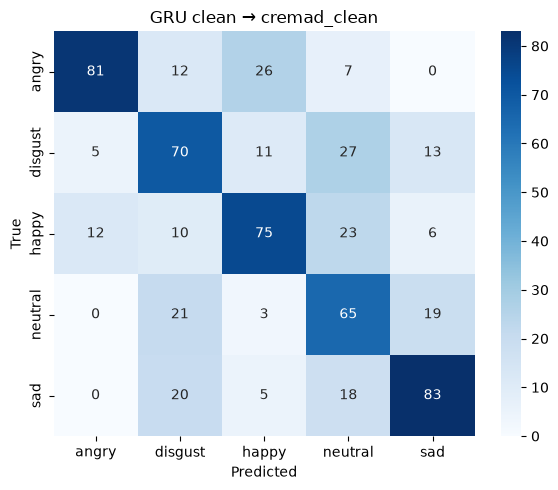

CRNN clean → cremad_clean
              precision    recall  f1-score   support

       angry      0.910     0.643     0.753       126
     disgust      0.436     0.540     0.482       126
       happy      0.586     0.516     0.549       126
     neutral      0.607     0.500     0.548       108
         sad      0.587     0.778     0.669       126

    accuracy                          0.598       612
   macro avg      0.625     0.595     0.600       612
weighted avg      0.626     0.598     0.602       612



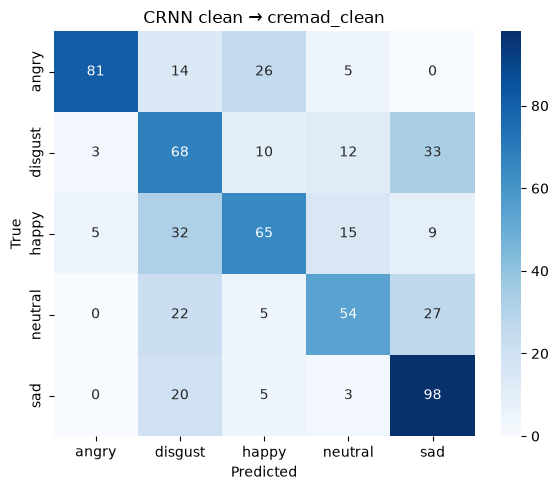

GRU clean → cremad_degraded
              precision    recall  f1-score   support

       angry      0.207     0.984     0.343       126
     disgust      0.000     0.000     0.000       126
       happy      0.071     0.008     0.014       126
     neutral      0.000     0.000     0.000       108
         sad      0.000     0.000     0.000       126

    accuracy                          0.204       612
   macro avg      0.056     0.198     0.071       612
weighted avg      0.057     0.204     0.073       612



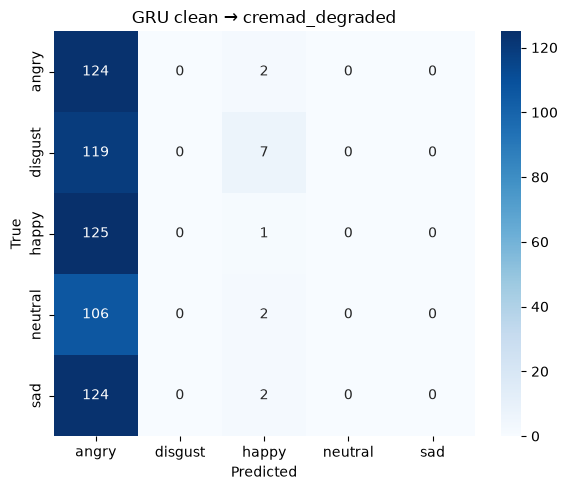

CRNN clean → cremad_degraded
              precision    recall  f1-score   support

       angry      0.134     0.214     0.165       126
     disgust      0.457     0.167     0.244       126
       happy      0.247     0.714     0.367       126
     neutral      0.000     0.000     0.000       108
         sad      0.000     0.000     0.000       126

    accuracy                          0.225       612
   macro avg      0.167     0.219     0.155       612
weighted avg      0.172     0.225     0.160       612



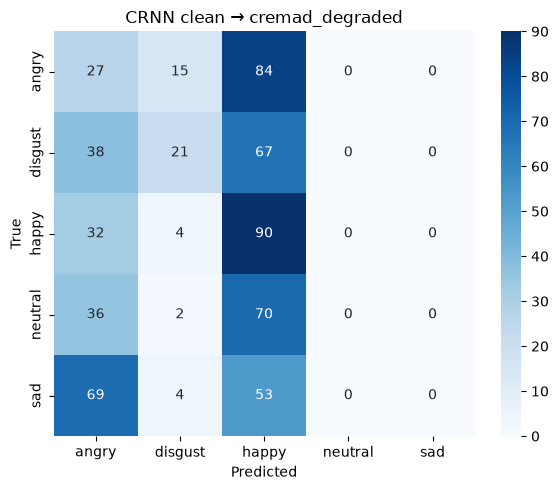

GRU messy → cremad_clean
              precision    recall  f1-score   support

       angry      0.859     0.627     0.725       126
     disgust      0.552     0.508     0.529       126
       happy      0.571     0.603     0.587       126
     neutral      0.488     0.546     0.515       108
         sad      0.627     0.746     0.681       126

    accuracy                          0.608       612
   macro avg      0.619     0.606     0.607       612
weighted avg      0.623     0.608     0.610       612



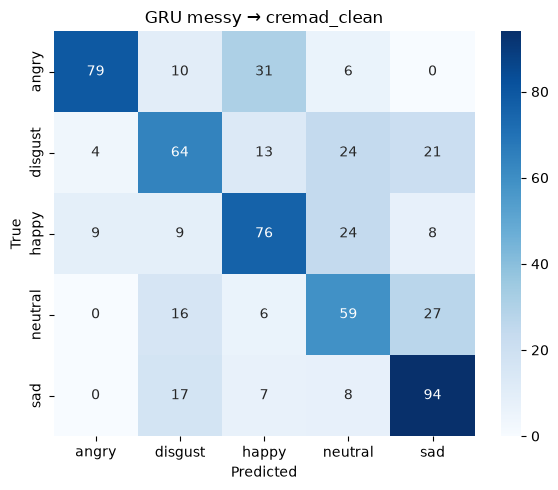

CRNN messy → cremad_clean
              precision    recall  f1-score   support

       angry      0.848     0.667     0.747       126
     disgust      0.610     0.397     0.481       126
       happy      0.558     0.683     0.614       126
     neutral      0.517     0.574     0.544       108
         sad      0.637     0.794     0.707       126

    accuracy                          0.624       612
   macro avg      0.634     0.623     0.618       612
weighted avg      0.638     0.624     0.621       612



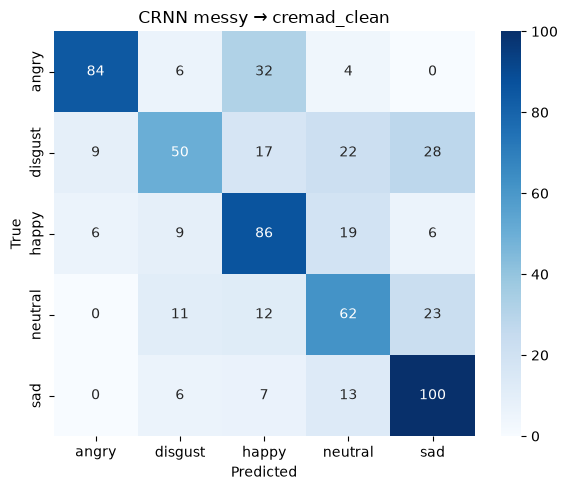

GRU messy → cremad_degraded
              precision    recall  f1-score   support

       angry      0.228     0.683     0.341       126
     disgust      0.889     0.063     0.119       126
       happy      0.219     0.389     0.280       126
     neutral      0.000     0.000     0.000       108
         sad      0.000     0.000     0.000       126

    accuracy                          0.234       612
   macro avg      0.267     0.227     0.148       612
weighted avg      0.275     0.234     0.152       612



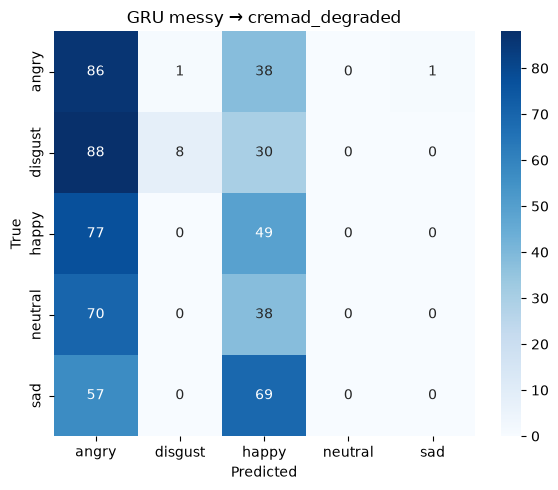

CRNN messy → cremad_degraded
              precision    recall  f1-score   support

       angry      0.310     0.746     0.438       126
     disgust      0.217     0.040     0.067       126
       happy      0.227     0.500     0.312       126
     neutral      0.000     0.000     0.000       108
         sad      1.000     0.063     0.119       126

    accuracy                          0.278       612
   macro avg      0.351     0.270     0.187       612
weighted avg      0.361     0.278     0.193       612



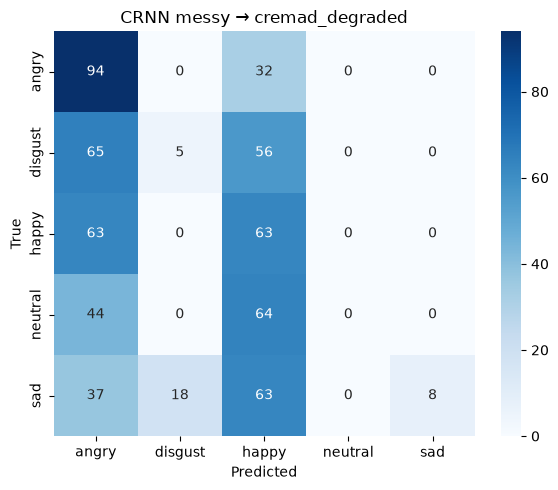

model train_condition        test_set  accuracy  macro_f1
  GRU           clean    cremad_clean  0.611111  0.613954
 CRNN           clean    cremad_clean  0.598039  0.600289
  GRU           clean cremad_degraded  0.204248  0.071365
 CRNN           clean cremad_degraded  0.225490  0.155233
  GRU           messy    cremad_clean  0.607843  0.607402
 CRNN           messy    cremad_clean  0.624183  0.618459
  GRU           messy cremad_degraded  0.233660  0.147958
 CRNN           messy cremad_degraded  0.277778  0.187325


In [18]:
gru = tf.keras.models.load_model(MODEL_DIR / "gru_clean.keras")
crnn = tf.keras.models.load_model(MODEL_DIR / "crnn_clean.keras")
gru_m = tf.keras.models.load_model(MODEL_DIR / "gru_messy.keras")
crnn_m = tf.keras.models.load_model(MODEL_DIR / "crnn_messy.keras")


def eval_row(model, X, y, model_name, train_cond, test_name, cm_path):
    m = evaluate(model, X, y, f"{model_name} {train_cond} → {test_name}", cm_path)
    row = {
        "model": model_name,
        "train_condition": train_cond,
        "test_set": test_name,
        "accuracy": m["accuracy"],
        "macro_f1": m["macro_f1"],
        "n_test": int(len(y)),
        "seed": SEED,
    }
    for i, e in enumerate(EMOTIONS):
        row[f"f1_{e}"] = float(m["per_class_f1"][i])
    return row


jobs = [
    (gru, X_te, y_te, "GRU", "clean", "cremad_clean", "cm_gru_clean_cremad.png"),
    (crnn, X_te_c, y_te, "CRNN", "clean", "cremad_clean", "cm_crnn_clean_cremad.png"),
    (gru, X_te_deg, y_te_deg, "GRU", "clean", "cremad_degraded", "cm_gru_clean_degraded.png"),
    (crnn, X_te_deg_c, y_te_deg, "CRNN", "clean", "cremad_degraded", "cm_crnn_clean_degraded.png"),
    (gru_m, X_te, y_te, "GRU", "messy", "cremad_clean", "cm_gru_messy_cremad.png"),
    (crnn_m, X_te_c, y_te, "CRNN", "messy", "cremad_clean", "cm_crnn_messy_cremad.png"),
    (gru_m, X_te_deg, y_te_deg, "GRU", "messy", "cremad_degraded", "cm_gru_messy_degraded.png"),
    (crnn_m, X_te_deg_c, y_te_deg, "CRNN", "messy", "cremad_degraded", "cm_crnn_messy_degraded.png"),
]
results_all = pd.DataFrame([
    eval_row(model, X, y, name, cond, test, OUT_DIR / png)
    for model, X, y, name, cond, test, png in jobs
])
results_all.to_csv(OUT_DIR / "results_clean_vs_messy.csv", index=False)
print(results_all[["model", "train_condition", "test_set", "accuracy", "macro_f1"]].to_string(index=False))


Write a LaTeX tabular for Overleaf (`outputs/table_clean_vs_messy.tex`).
This is for the report


In [19]:
def write_results_tex(df, path):
    lines = [
        r"\begin{tabular}{lllcc}",
        r"\hline",
        r"Model & Train & Test & Accuracy & Macro-F1 \\",
        r"\hline",
    ]
    for _, r in df.iterrows():
        test = "clean" if r["test_set"] == "cremad_clean" else "degraded"
        lines.append(
            f"{r['model']} & {r['train_condition']} & {test} & "
            f"{r['accuracy']:.6f} & {r['macro_f1']:.6f} \\\\"
        )
    lines += [r"\hline", r"\end{tabular}", ""]
    path.write_text("\n".join(lines))


write_results_tex(results_all, OUT_DIR / "table_clean_vs_messy.tex")
print("Wrote", relpath(OUT_DIR / "table_clean_vs_messy.tex"))


Wrote outputs/table_clean_vs_messy.tex


Turn the CSV into a compact accuracy table image.


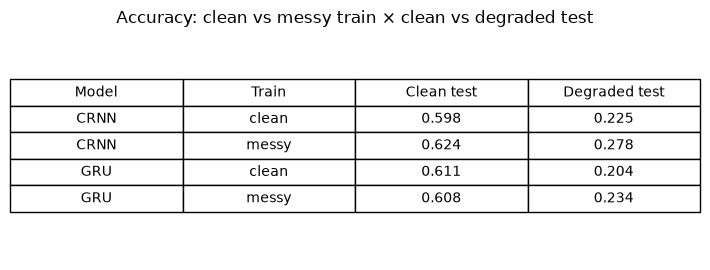

In [20]:
pivot = results_all.pivot_table(index=["model", "train_condition"], columns="test_set", values="accuracy")
fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.axis("off")
ax.set_title("Accuracy: clean vs messy train × clean vs degraded test")
cells = [
    [model, cond, f"{r['cremad_clean']:.3f}", f"{r['cremad_degraded']:.3f}"]
    for (model, cond), r in pivot.iterrows()
]
tbl = ax.table(
    cellText=cells,
    colLabels=["Model", "Train", "Clean test", "Degraded test"],
    loc="center",
    cellLoc="center",
)
tbl.scale(1, 1.5)
fig.tight_layout()
fig.savefig(OUT_DIR / "table_clean_vs_messy.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()


## 14. Extra figures

Per-class F1 on the **degraded** test (where messy training is supposed to matter), and loss curves if we trained this session instead of loading a checkpoint.


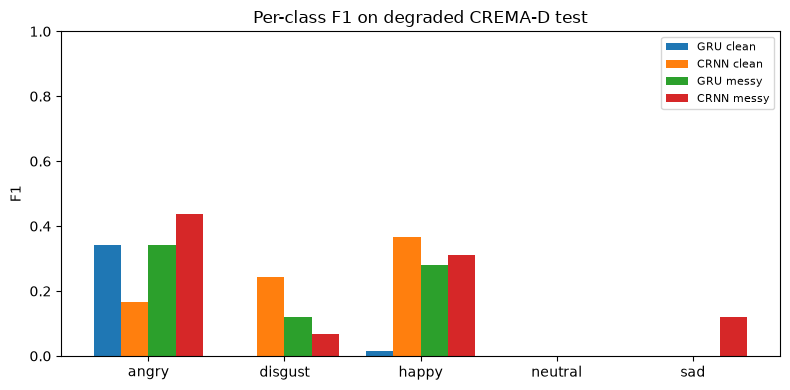

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
sub = results_all[results_all["test_set"] == "cremad_degraded"]
x = np.arange(len(EMOTIONS))
width = 0.2
series = [("GRU clean", "GRU", "clean"), ("CRNN clean", "CRNN", "clean"),
          ("GRU messy", "GRU", "messy"), ("CRNN messy", "CRNN", "messy")]
for i, (label, model, cond) in enumerate(series):
    row = sub[(sub["model"] == model) & (sub["train_condition"] == cond)].iloc[0]
    ax.bar(x + (i - 1.5) * width, [row[f"f1_{e}"] for e in EMOTIONS], width, label=label)
ax.set_xticks(x)
ax.set_xticklabels(EMOTIONS)
ax.set_ylabel("F1")
ax.set_ylim(0, 1)
ax.set_title("Per-class F1 on degraded CREMA-D test")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_f1_degraded.png", dpi=150)
plt.show()
plt.close()


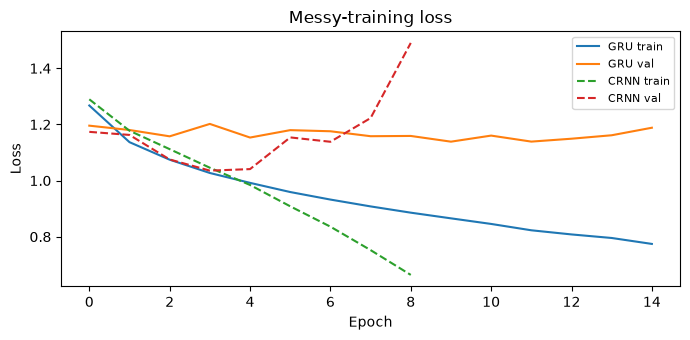

In [22]:
if hist_gru_m is None and hist_crnn_m is None:
    print("Messy models were loaded from disk, so there is no new loss curve.")
else:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    if hist_gru_m is not None:
        ax.plot(hist_gru_m.history["loss"], label="GRU train")
        ax.plot(hist_gru_m.history["val_loss"], label="GRU val")
    if hist_crnn_m is not None:
        ax.plot(hist_crnn_m.history["loss"], "--", label="CRNN train")
        ax.plot(hist_crnn_m.history["val_loss"], "--", label="CRNN val")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_title("Messy-training loss")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig_messy_loss.png", dpi=150)
    plt.show()
    plt.close()


## 15. Demo on real speech (no labels)

Publicly available White House montage (2017). Licence was not verified for this report, so it is not described as public domain. We extract audio, slide a 2 s window every 0.2 s, and **plot predictions**. Do not report accuracy here — the clip is not labelled.

Cite: The White House, *Yes We Can: People Share Their Most Memorable Moments from the Obama Presidency*, 2017.


In [23]:
WINDOW_S = 2.0
HOP_S = 0.2

if not VIDEO_PATH.is_file():
    raise FileNotFoundError("Missing demo video in test_video/")

wav_demo = CACHE_DIR / "yes_we_can.wav"
if not wav_demo.exists():
    ff = imageio_ffmpeg.get_ffmpeg_exe()
    subprocess.check_call([ff, "-y", "-i", str(VIDEO_PATH), "-ac", "1", "-ar", str(SR), str(wav_demo)])

y_demo, _ = sf.read(wav_demo, dtype="float32", always_2d=False)
duration = len(y_demo) / SR
print("Demo duration (s):", round(duration, 1))


Demo duration (s): 349.7


Cut overlapping windows, convert each to MFCCs, then run the **messy-trained** models (the ones meant for imperfect audio). A later cell also runs the **clean-trained** models on the same windows for a qualitative comparison of predicted-class shares. Still no accuracy: there are no labels.


In [24]:
win = int(WINDOW_S * SR)
hop = int(HOP_S * SR)
starts = list(range(0, max(1, len(y_demo) - win + 1), hop))

feats, times = [], []
for st in tqdm(starts, desc="demo windows"):
    times.append(st / SR)
    feats.append(mfcc_from_wav(y_demo[st:st + win]))

X_demo = np.stack(feats)
p_gru = gru_m.predict(X_demo, batch_size=64, verbose=0)
p_crnn = crnn_m.predict(X_demo[..., np.newaxis], batch_size=64, verbose=0)
gru_top = np.argmax(p_gru, axis=1)
crnn_top = np.argmax(p_crnn, axis=1)
print("Windows:", len(times))


demo windows: 100%|██████████| 1739/1739 [00:02<00:00, 710.70it/s]


Windows: 1739


Predicted-class **shares** on the unlabelled demo windows (clean-trained vs messy-trained). This is not an accuracy table.


In [25]:
def class_shares(probs, model_name, train_cond):
    pred = np.argmax(probs, axis=1)
    counts = pd.Series(pred).value_counts(normalize=True)
    row = {"model": model_name, "train_condition": train_cond, "n_windows": int(len(pred))}
    for i, e in enumerate(EMOTIONS):
        row[e] = float(counts.get(i, 0.0))
    return row


p_gru_clean = gru.predict(X_demo, batch_size=64, verbose=0)
p_crnn_clean = crnn.predict(X_demo[..., np.newaxis], batch_size=64, verbose=0)

demo_shares = pd.DataFrame([
    class_shares(p_gru_clean, "GRU", "clean"),
    class_shares(p_crnn_clean, "CRNN", "clean"),
    class_shares(p_gru, "GRU", "messy"),
    class_shares(p_crnn, "CRNN", "messy"),
])
demo_shares.to_csv(OUT_DIR / "demo_pred_class_shares.csv", index=False)
print(demo_shares.to_string(index=False))


model train_condition  n_windows    angry  disgust    happy  neutral      sad
  GRU           clean       1739 0.573893 0.026452 0.284646 0.070155 0.044853
 CRNN           clean       1739 0.251294 0.253594 0.410006 0.034503 0.050604
  GRU           messy       1739 0.105808 0.427257 0.108108 0.095457 0.263370
 CRNN           messy       1739 0.000575 0.169638 0.236343 0.121334 0.472110


Line plots: most likely emotion vs time. The first seconds are often music, so the labels there can look random.


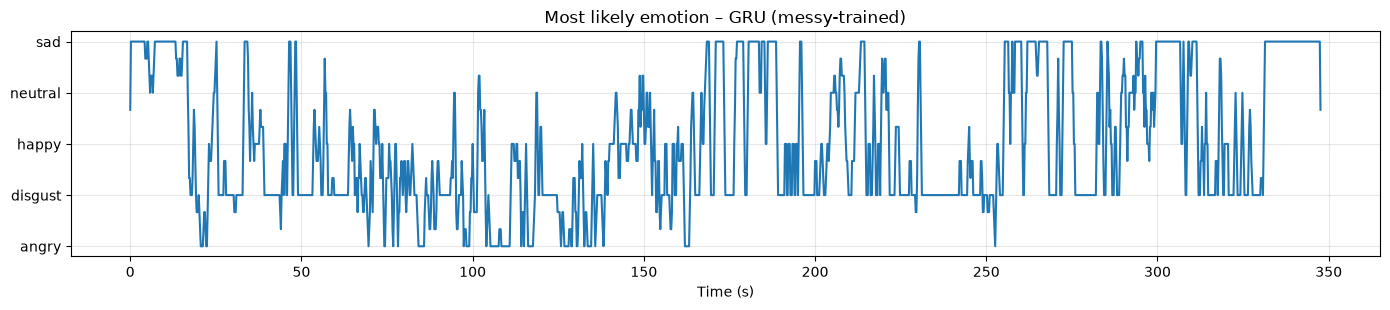

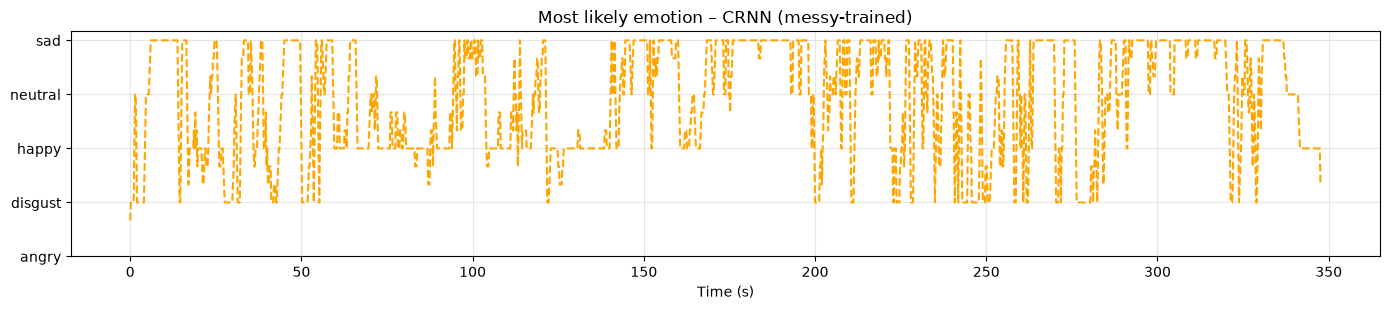

In [26]:
def smooth(x, k=3):
    return np.convolve(x, np.ones(k) / k, mode="same")


def save_line(times, series, title, path, style=None):
    plt.figure(figsize=(14, 3.2))
    plt.plot(times, smooth(series, 3), **(style or {}))
    plt.yticks(ticks=np.arange(len(EMOTIONS)), labels=EMOTIONS)
    plt.title(title)
    plt.xlabel("Time (s)")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()
    plt.close()


save_line(times, gru_top, "Most likely emotion – GRU (messy-trained)", OUT_DIR / "demo_gru_line.png")
save_line(
    times, crnn_top, "Most likely emotion – CRNN (messy-trained)",
    OUT_DIR / "demo_crnn_line.png", {"linestyle": "--", "color": "orange"},
)


Colour bar (one colour per predicted class along time), plus a probability heatmap for the CRNN.


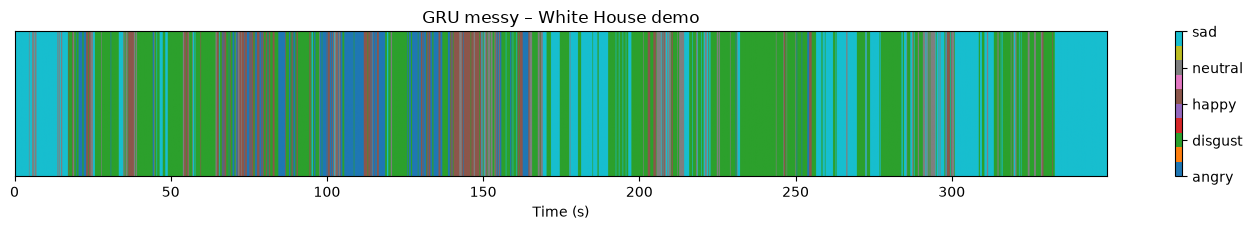

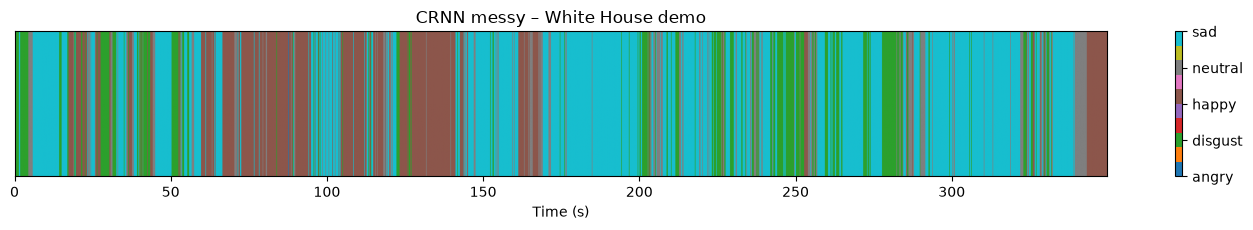

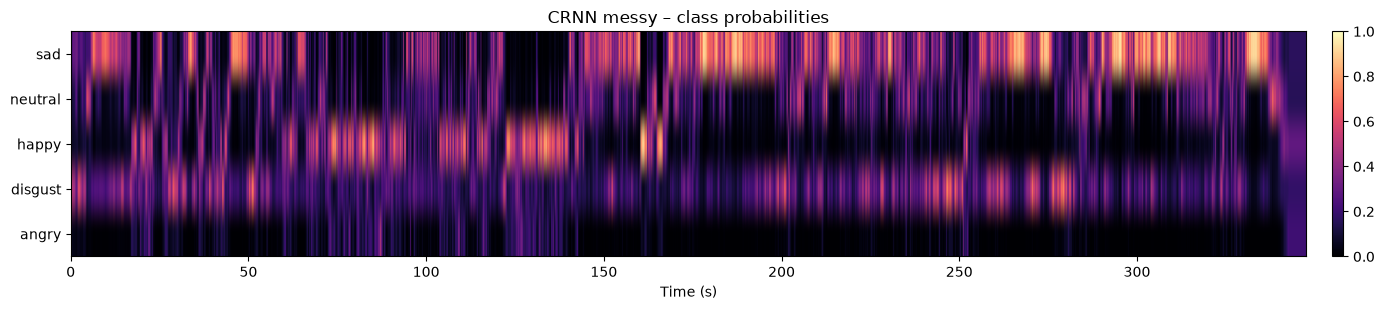

In [27]:
def plot_timeline(emotion_idxs, title, duration, out_path):
    plt.figure(figsize=(14, 2.4))
    plt.title(title)
    plt.imshow(
        [emotion_idxs], aspect="auto", cmap="tab10",
        extent=[0, duration, 0, 1], vmin=0, vmax=len(EMOTIONS) - 1,
    )
    plt.yticks([])
    plt.xlabel("Time (s)")
    cbar = plt.colorbar(ticks=np.arange(len(EMOTIONS)))
    cbar.ax.set_yticklabels(EMOTIONS)
    plt.tight_layout()
    plt.savefig(out_path, dpi=150)
    plt.show()
    plt.close()


plot_timeline(gru_top, "GRU messy – White House demo", duration, OUT_DIR / "demo_gru_timeline.png")
plot_timeline(crnn_top, "CRNN messy – White House demo", duration, OUT_DIR / "demo_crnn_timeline.png")

fig, ax = plt.subplots(figsize=(14, 3.2))
im = ax.imshow(
    p_crnn.T, aspect="auto", origin="lower",
    extent=[times[0], times[-1], -0.5, 4.5], cmap="magma", vmin=0, vmax=1,
)
ax.set_yticks(range(5))
ax.set_yticklabels(EMOTIONS)
ax.set_xlabel("Time (s)")
ax.set_title("CRNN messy – class probabilities")
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.02)
fig.tight_layout()
fig.savefig(OUT_DIR / "demo_crnn_probs.png", dpi=150)
plt.show()
plt.close()


Dominant predicted emotion in each 10-second block, same summary table as the original demo.


In [28]:
def dominant_table(preds, times, duration, interval=10):
    rows = []
    edges = np.arange(0, duration + interval, interval)
    for start, end in zip(edges[:-1], edges[1:]):
        idxs = [j for j, t in enumerate(times) if start <= t < end]
        if not idxs:
            emo = "No data"
        else:
            vals, counts = np.unique(preds[idxs], return_counts=True)
            emo = EMOTIONS[int(vals[np.argmax(counts)])]
        rows.append({"Time Range": f"{int(start)}–{int(end)}s", "Dominant Emotion": emo})
    return pd.DataFrame(rows)


df_gru = dominant_table(gru_top, times, duration)
df_crnn = dominant_table(crnn_top, times, duration)
df_gru.to_csv(OUT_DIR / "demo_gru_10s.csv", index=False)
df_crnn.to_csv(OUT_DIR / "demo_crnn_10s.csv", index=False)
print("GRU\n", df_gru.to_string(index=False))
print("CRNN\n", df_crnn.to_string(index=False))


GRU
 Time Range Dominant Emotion
     0–10s              sad
    10–20s              sad
    20–30s          disgust
    30–40s          disgust
    40–50s          disgust
    50–60s          disgust
    60–70s          disgust
    70–80s            happy
    80–90s          disgust
   90–100s          disgust
  100–110s            angry
  110–120s            angry
  120–130s          disgust
  130–140s            angry
  140–150s            happy
  150–160s          disgust
  160–170s          disgust
  170–180s              sad
  180–190s              sad
  190–200s          disgust
  200–210s          disgust
  210–220s          disgust
  220–230s          disgust
  230–240s          disgust
  240–250s          disgust
  250–260s          disgust
  260–270s              sad
  270–280s          disgust
  280–290s          disgust
  290–300s              sad
  300–310s              sad
  310–320s          disgust
  320–330s          disgust
  330–340s              sad
  340–350s     

## Limitations

- **Simulated test only.** Degraded CREMA-D is phone band-limiting + reverb + noise (sometimes cut-off) on acted studio clips. It is not labelled real-world audio.
- **No real labelled evaluation.** MELD and self-labelled clips were not used. The White House demo has no emotion labels, so it cannot support an accuracy claim.
- **Single seed.** All splits and training used 1 seed only.
- **Small test set.** 9 speakers, 612 clips.
- **Train/test degradation mismatch.** Messy training adds *separate* extra copies (one augmentation each). The degraded test *combines* phone band-limit + reverb + noise, and cut-off on a subset.
- **Class collapse under degradation.** On degraded audio the clean GRU, in particular, often predicts **angry** and other classes can have F1 of 0 (see per-class F1 columns in `outputs/results_clean_vs_messy.csv`).
- **GRU masking.** `Masking(mask_value=0.0)` is kept from the prototype but is unlikely to mask padded MFCC frames.
